# 🎯 Task-Specific EDA: Continuous & Ordinal Text Regression
## Target Distribution, Skewness, Length Correlation & Optimization Metric Diagnostics
**Kit:** `01_NLU/02_text_regression` | **Standard:** GEMASTIK XIX 2026 & Kaggle NLP  
**Focus:** Continuous values, essay grading (AES), readability index, sentiment scores, and ordinal metrics (RMSE, MAE, QWK).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

train_path = '../demo_data/train.csv'
test_path  = '../demo_data/test.csv'

train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)

print(f"Train rows: {len(train_df)} | Test rows: {len(test_df)}")
train_df.head()


Train rows: 60 | Test rows: 20


,id,full_text,prompt_text,prompt_id,category,word_count,score,grade,toxicity,likes_count,cohesion,syntax,vocabulary
0,TRAIN_0001,The rapid advancement of environment has funda...,Jelaskan pengaruh kecerdasan buatan terhadap m...,P102,Environment,59,4.353,5,0.1695,13,4.33,4.17,4.18
1,TRAIN_0002,Kecerdasan buatan dan inovasi teknologi membaw...,Analyze the advantages and disadvantages of re...,P103,Society,51,4.247,5,0.0531,9,4.16,4.13,4.06
2,TRAIN_0003,The rapid advancement of education has fundame...,Bagaimana peran pemuda dalam memajukan inovasi...,P104,Education,63,3.873,4,0.0535,12,3.82,3.84,3.58
3,TRAIN_0004,Kecerdasan buatan dan inovasi teknologi membaw...,Discuss the ethical implications of genetic en...,P105,Science,68,3.255,4,0.1389,8,3.55,3.13,3.44
4,TRAIN_0005,The rapid advancement of technology has fundam...,Describe the impact of renewable energy on glo...,P101,Technology,53,2.793,3,0.1526,11,2.69,2.79,2.75


In [2]:
# Detect target column (numeric column not in test)
candidate_targets = [col for col in train_df.columns if col not in test_df.columns and pd.api.types.is_numeric_dtype(train_df[col])]
TARGET_COL = candidate_targets[0] if candidate_targets else 'score'
print(f"Detected Target Column: '{TARGET_COL}'")

target = train_df[TARGET_COL].dropna()
mean_val = target.mean()
median_val = target.median()
std_val = target.std()
skew_val = target.skew()
kurt_val = target.kurtosis()

print("--- TARGET DESCRIPTIVE STATISTICS ---")
print(f"Count    : {len(target)}")
print(f"Mean     : {mean_val:.4f}")
print(f"Median   : {median_val:.4f}")
print(f"Std Dev  : {std_val:.4f}")
print(f"Min / Max: {target.min():.4f} / {target.max():.4f}")
print(f"Skewness : {skew_val:.4f} (Rule: |skew| > 1.0 indicates severe skew)")
print(f"Kurtosis : {kurt_val:.4f}")


Detected Target Column: 'score'
--- TARGET DESCRIPTIVE STATISTICS ---
Count    : 60
Mean     : 3.7148
Median   : 3.7095
Std Dev  : 0.5799
Min / Max: 2.7600 / 4.5740
Skewness : -0.0692 (Rule: |skew| > 1.0 indicates severe skew)
Kurtosis : -1.4650


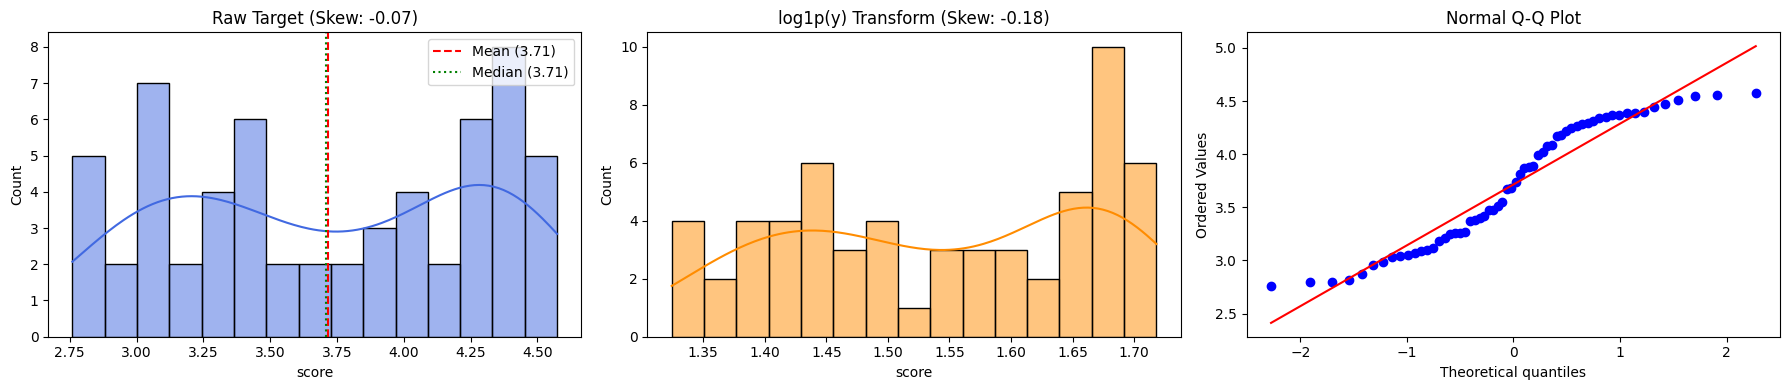

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Raw Target Distribution
sns.histplot(target, kde=True, ax=axes[0], color='royalblue', bins=15)
axes[0].axvline(mean_val, color='red', linestyle='--', label=f'Mean ({mean_val:.2f})')
axes[0].axvline(median_val, color='green', linestyle=':', label=f'Median ({median_val:.2f})')
axes[0].set_title(f"Raw Target (Skew: {skew_val:.2f})")
axes[0].legend()

# 2. Log1p Transformation
if (target >= 0).all():
    log_target = np.log1p(target)
    sns.histplot(log_target, kde=True, ax=axes[1], color='darkorange', bins=15)
    axes[1].set_title(f"log1p(y) Transform (Skew: {log_target.skew():.2f})")
else:
    axes[1].text(0.5, 0.5, "Negative values present\n(log1p skipped)", ha='center')
    axes[1].set_title("log1p(y) (N/A)")

# 3. QQ-Plot for Normality
stats.probplot(target, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()


In [4]:
# Check if target is discrete or integer-stepped (common in essay scoring 1-6)
is_integer_stepped = (target.round() == target).all()
unique_steps = sorted(target.unique())

print(f"Is Target Discrete/Integer-stepped? : {is_integer_stepped}")
print(f"Unique Target Values ({len(unique_steps)}) : {unique_steps}")

if is_integer_stepped and len(unique_steps) <= 10:
    print("\n🎯 DIAGNOSTIC: Target is DISCRETE / ORDINAL (e.g. Essay Grading 1-6).")
    print("-> Recommendation: Train regression with MSE / SmoothL1, then calibrate with Nelder-Mead QWK Cutter!")
else:
    print("\n🎯 DIAGNOSTIC: Target is CONTINUOUS (e.g. Readability / Sentiment continuous index).")
    print("-> Recommendation: Train regression with MSE / Huber Loss, apply Bounded Clipping Post-Processing.")


Is Target Discrete/Integer-stepped? : False
Unique Target Values (60) : [np.float64(2.76), np.float64(2.793), np.float64(2.796), np.float64(2.817), np.float64(2.87), np.float64(2.959), np.float64(2.987), np.float64(3.029), np.float64(3.043), np.float64(3.047), np.float64(3.071), np.float64(3.085), np.float64(3.095), np.float64(3.12), np.float64(3.185), np.float64(3.213), np.float64(3.25), np.float64(3.255), np.float64(3.257), np.float64(3.265), np.float64(3.371), np.float64(3.383), np.float64(3.396), np.float64(3.417), np.float64(3.474), np.float64(3.476), np.float64(3.513), np.float64(3.55), np.float64(3.674), np.float64(3.679), np.float64(3.74), np.float64(3.813), np.float64(3.873), np.float64(3.877), np.float64(3.89), np.float64(3.997), np.float64(4.017), np.float64(4.076), np.float64(4.089), np.float64(4.169), np.float64(4.18), np.float64(4.223), np.float64(4.247), np.float64(4.261), np.float64(4.289), np.float64(4.296), np.float64(4.31), np.float64(4.34), np.float64(4.353), np.flo

Text Column: 'full_text'
Word Count vs Target -> Pearson: -0.0093 | Spearman: -0.0162


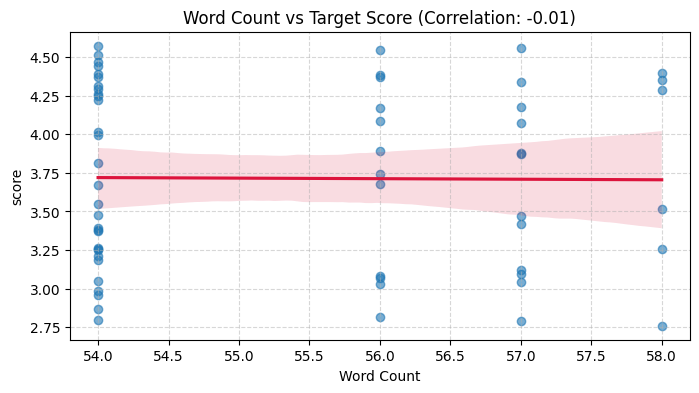

In [5]:
text_candidates = [c for c in train_df.columns if train_df[c].dtype == 'object' and c != 'id']
TEXT_COL = text_candidates[0] if text_candidates else 'full_text'

train_df['word_count'] = train_df[TEXT_COL].astype(str).apply(lambda x: len(x.split()))
train_df['char_count'] = train_df[TEXT_COL].astype(str).apply(len)

pearson_wc = train_df['word_count'].corr(train_df[TARGET_COL], method='pearson')
spearman_wc = train_df['word_count'].corr(train_df[TARGET_COL], method='spearman')

print(f"Text Column: '{TEXT_COL}'")
print(f"Word Count vs Target -> Pearson: {pearson_wc:.4f} | Spearman: {spearman_wc:.4f}")

plt.figure(figsize=(8, 4))
sns.regplot(data=train_df, x='word_count', y=TARGET_COL, scatter_kws={'alpha': 0.6}, line_kws={'color': 'crimson'})
plt.title(f"Word Count vs Target Score (Correlation: {pearson_wc:.2f})")
plt.xlabel("Word Count")
plt.ylabel(TARGET_COL)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

if abs(pearson_wc) > 0.4:
    print("🚨 HIGH LEAKAGE / HIGH SIGNAL: Text length is strongly correlated with target!")
    print("-> GBDT with text length features alone will provide a massive baseline boost!")


### 📋 Master Decision Matrix (Text Regression):
| Diagnostic Signal | Condition | Recommended Strategy |
| :--- | :--- | :--- |
| **Skewness** | $|\text{skew}| > 1.0$ | Apply `np.log1p(y)` target transformation during training, `np.expm1(p)` during inference. |
| **Ordinal Steps** | Target $\in \{1, 2, 3, 4, 5, 6\}$ | Train continuous MSE/Huber, apply Nelder-Mead threshold cutter for QWK. |
| **Length Correlation** | Pearson $|r| > 0.40$ | Heavily leverage surface text length features in GBDT baseline. |
| **Loss Function** | Extreme outliers present | Switch from MSE to Huber Loss ($\delta=1.0$) to avoid gradient explosion. |
